# 01 — Dados: download, limpeza e grade (R1, R2, R3)
Baixa os focos do FIRMS (Brasil), filtra e conta por **célula 0,25° × mês × sensor**.

In [1]:
import requests, duckdb, pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

RAW, PROC = Path('../data/raw'), Path('../data/processed')
RAW.mkdir(parents=True, exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
PAIS = 'Brazil'
BASE = 'https://firms.modaps.eosdis.nasa.gov/data/country'
FONTES = {'modis': range(2001, 2026), 'viirs-snpp': range(2012, 2026)}
COLS = ['latitude','longitude','acq_date','acq_time','satellite','confidence','frp','daynight','type']
CELULA, BLOCO = 0.25, 5.0   # grade do calendário / blocos para o fator k

## R1 — Download
Cada CSV anual vira Parquet (só colunas úteis) e o CSV é apagado para economizar espaço. Anos que não existem (404) são pulados.

In [2]:
def baixar(fonte, ano):
    out = RAW / f'{fonte}_{ano}.parquet'
    if out.exists(): return f'{out.name} (já existe)'
    url = f'{BASE}/{fonte}/{ano}/{fonte}_{ano}_{PAIS}.csv'
    tmp = RAW / f'{fonte}_{ano}.csv'
    with requests.get(url, stream=True, timeout=120) as r:
        if r.status_code == 404: return f'{fonte} {ano}: não disponível'
        r.raise_for_status()
        with open(tmp, 'wb') as f:
            for chunk in r.iter_content(1 << 20): f.write(chunk)
    df = pd.read_csv(tmp, usecols=COLS, dtype={'confidence': str, 'acq_time': str})
    df.to_parquet(out, index=False); tmp.unlink()
    return f'{out.name}: {len(df):,} focos'

tarefas = [(f, a) for f, anos in FONTES.items() for a in anos]
with ThreadPoolExecutor(4) as ex:
    for msg in ex.map(lambda t: baixar(*t), tarefas): print(msg)

modis_2001.parquet: 145,721 focos


modis_2002.parquet: 524,224 focos
modis_2003.parquet: 548,388 focos


modis_2004.parquet: 634,507 focos


modis_2005.parquet: 631,834 focos
modis_2006.parquet: 406,646 focos


modis_2007.parquet: 700,531 focos
modis_2008.parquet: 354,521 focos


modis_2009.parquet: 250,516 focos


... (11 outputs left out)

viirs-snpp_2015.parquet: 1,718,574 focos
viirs-snpp_2016.parquet: 1,303,403 focos
viirs-snpp_2017.parquet: 1,543,270 focos


viirs-snpp_2018.parquet: 915,584 focos
viirs-snpp_2019.parquet: 1,459,285 focos
viirs-snpp_2020.parquet: 1,666,244 focos
viirs-snpp_2021.parquet: 1,333,192 focos
viirs-snpp_2022.parquet: 1,405,383 focos


viirs-snpp_2023.parquet: 1,345,502 focos


viirs-snpp_2024.parquet: 1,935,740 focos
viirs-snpp_2025.parquet: 861,621 focos


## R2 + R3 — Filtro e grade
- `type = 0` (vegetação; tira flares, vulcões, offshore)
- MODIS `confidence >= 30`, VIIRS `confidence in (n, h)`
- Célula = `floor(coord / 0.25) * 0.25`

In [3]:
con = duckdb.connect()
grid = con.execute(f'''
WITH focos AS (
  SELECT *, 'modis' AS sensor FROM read_parquet('{RAW.as_posix()}/modis_*.parquet')
   WHERE type = 0 AND TRY_CAST(confidence AS INT) >= 30
  UNION ALL BY NAME
  SELECT *, 'viirs' AS sensor FROM read_parquet('{RAW.as_posix()}/viirs-snpp_*.parquet')
   WHERE type = 0 AND confidence IN ('n','h')
)
SELECT floor(latitude/{CELULA})*{CELULA}  AS lat,
       floor(longitude/{CELULA})*{CELULA} AS lon,
       year(CAST(acq_date AS DATE))  AS ano,
       month(CAST(acq_date AS DATE)) AS mes,
       count(*) FILTER (WHERE sensor='modis') AS n_modis,
       count(*) FILTER (WHERE sensor='viirs') AS n_viirs
FROM focos GROUP BY ALL
''').df()
grid['bloco_lat'] = (grid.lat // BLOCO) * BLOCO
grid['bloco_lon'] = (grid.lon // BLOCO) * BLOCO
grid.to_parquet(PROC / 'grid_monthly.parquet', index=False)
print(f'{len(grid):,} linhas célula×mês'); grid.head()

1,291,215 linhas célula×mês


,lat,lon,ano,mes,n_modis,n_viirs,bloco_lat,bloco_lon
0,-9.25,-36.00,2009,1,19,0,-10.0,-40.0
1,-33.75,-53.50,2009,1,5,0,-35.0,-55.0
2,-6.75,-39.50,2009,1,5,0,-10.0,-40.0
3,-13.50,-45.75,2009,1,1,0,-15.0,-50.0
4,-6.25,-35.50,2009,1,4,0,-10.0,-40.0


## Checkpoint 1
Total anual por sensor. Esperado: VIIRS bem acima do MODIS a partir de 2012 → é esse degrau que a harmonização vai corrigir.

,n_modis,n_viirs,razao_viirs_modis
ano,,,
2001,136291,0,0.00
2002,490917,0,0.00
2003,507920,0,0.00
2004,579160,0,0.00
2005,594339,0,0.00
2006,383766,0,0.00
2007,662052,0,0.00
2008,337113,0,0.00
2009,237310,0,0.00


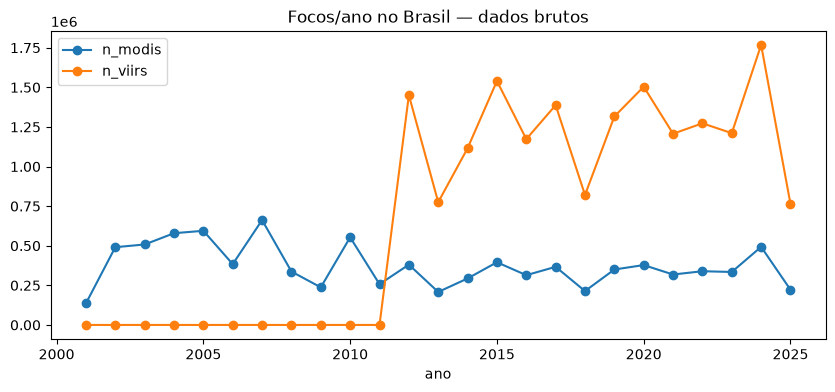

In [4]:
anual = grid.groupby('ano')[['n_modis','n_viirs']].sum()
anual['razao_viirs_modis'] = (anual.n_viirs / anual.n_modis).round(2)
ax = anual[['n_modis','n_viirs']].plot(marker='o', figsize=(10,4), title='Focos/ano no Brasil — dados brutos')
Path('../reports').mkdir(exist_ok=True)
ax.figure.savefig('../reports/checkpoint1_bruto.png', dpi=120, bbox_inches='tight')
anual